In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.dpi"] = 120

# File lives in the same folder as this notebook
XLSX = Path("generated_dataset.xlsx")

# Fallback to the absolute project path if the relative one isn't found
if not XLSX.exists():
    XLSX = Path(r"c:\Users\VAS1UL\Master Thesis\DC-Avaialable Baseversion\dc-available\evaluation\dataset_generation\generated_dataset.xlsx")

df = pd.read_excel(XLSX)
print("Loaded:", XLSX.resolve())
print("Shape:", df.shape)          # (1215, 8)
df.head(3)


Matplotlib is building the font cache; this may take a moment.


Loaded: C:\Users\VAS1UL\Master Thesis\DC-Avaialable Baseversion\dc-available\evaluation\dataset_generation\generated_dataset.xlsx
Shape: (1215, 8)


,topic,level,type,source_document,question,question_type,answer,keywords
0,DigitalTransformation,Basic,.png,20221129_EN_eT-B-Digit_FINAL.pptx,What are the key technologies driving Industry...,factual,Key technologies driving Industry 4.0 include ...,"IoT, AI, digital twins, cyber-physical systems..."
1,DigitalTransformation,Basic,.png,20221129_EN_eT-B-Digit_FINAL.pptx,How does the transition from Industry 3.0 to I...,conceptual,The transition from Industry 3.0 to Industry 4...,"Industry 3.0, Industry 4.0, decentralization, ..."
2,DigitalTransformation,Basic,.png,20221129_EN_eT-B-Digit_FINAL.pptx,What are the steps involved in implementing a ...,procedural,Implementing digital transformation involves s...,"digital transformation, connectivity, IT-OT in..."


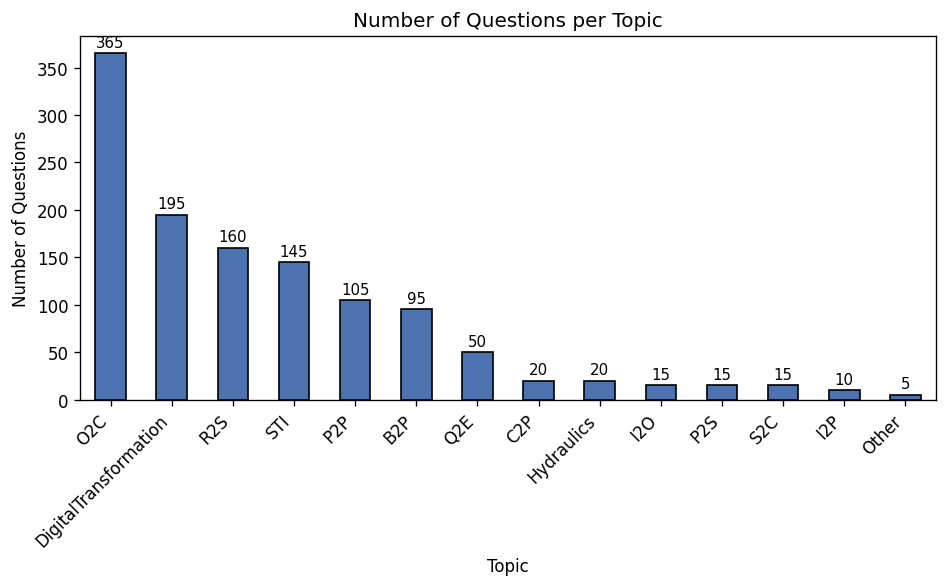

topic
O2C                      365
DigitalTransformation    195
R2S                      160
STI                      145
P2P                      105
B2P                       95
Q2E                       50
C2P                       20
Hydraulics                20
I2O                       15
P2S                       15
S2C                       15
I2P                       10
Other                      5
Name: count, dtype: int64


In [2]:
counts = df["topic"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="bar", color="#4C72B0", edgecolor="black", ax=ax)

ax.set_title("Number of Questions per Topic")
ax.set_xlabel("Topic")
ax.set_ylabel("Number of Questions")
plt.xticks(rotation=45, ha="right")

# value labels on top of each bar
for i, v in enumerate(counts):
    ax.text(i, v + max(counts) * 0.01, str(v), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

print(counts)   # also print the exact numbers


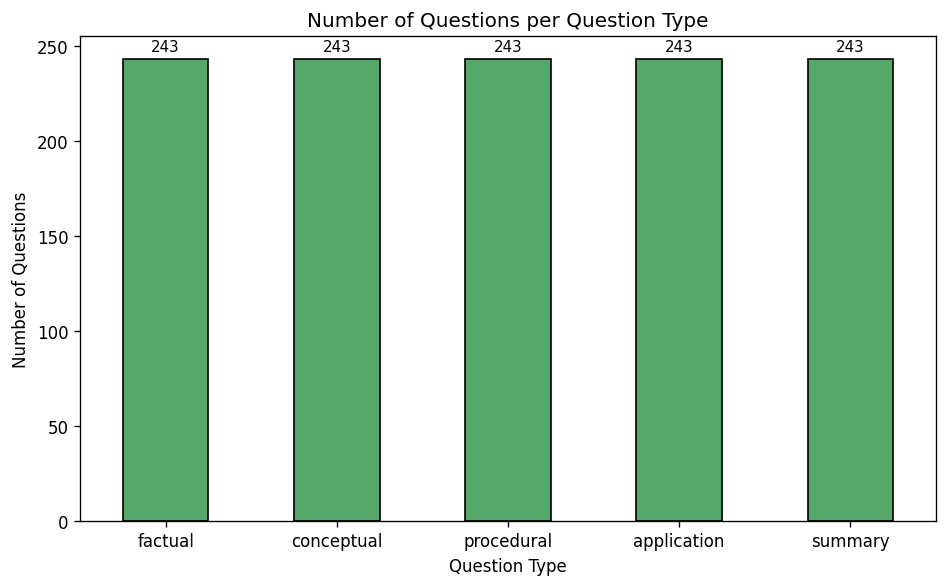

question_type
factual        243
conceptual     243
procedural     243
application    243
summary        243
Name: count, dtype: int64


In [3]:
counts = df["question_type"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="bar", color="#55A868", edgecolor="black", ax=ax)

ax.set_title("Number of Questions per Question Type")
ax.set_xlabel("Question Type")
ax.set_ylabel("Number of Questions")
plt.xticks(rotation=0)

# value labels on top of each bar
for i, v in enumerate(counts):
    ax.text(i, v + max(counts) * 0.01, str(v), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

print(counts)


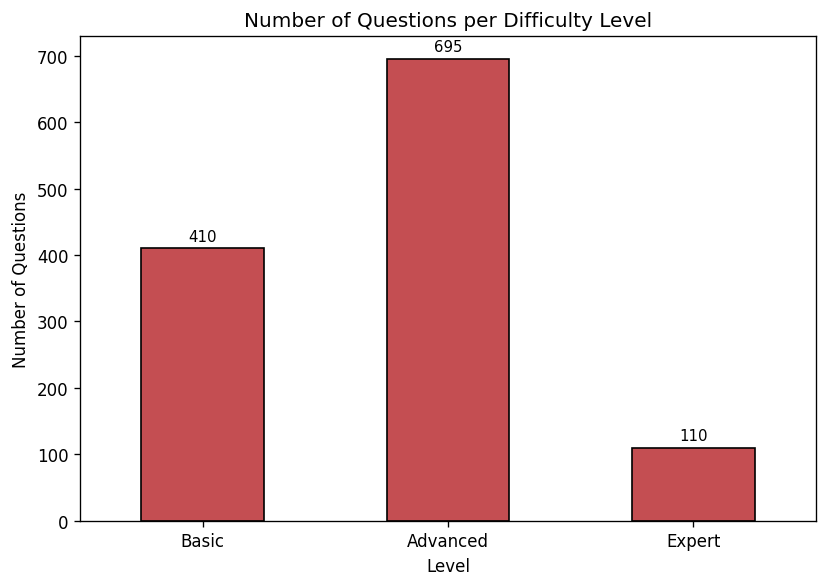

level
Basic       410
Advanced    695
Expert      110
Name: count, dtype: int64


In [10]:
# Actual levels in the data: Basic, Advanced, Expert (no "Intermediate")
level_order = ["Basic", "Advanced", "Expert"]
counts = df["level"].value_counts()

# keep only labels that exist, then append any unexpected ones so nothing is dropped
ordered = [l for l in level_order if l in counts.index]
ordered += [l for l in counts.index if l not in ordered]   # safety net
counts = counts.reindex(ordered)

fig, ax = plt.subplots(figsize=(7, 5))
counts.plot(kind="bar", color="#C44E52", edgecolor="black", ax=ax)

ax.set_title("Number of Questions per Difficulty Level")
ax.set_xlabel("Level")
ax.set_ylabel("Number of Questions")
plt.xticks(rotation=0)

for i, v in enumerate(counts):
    ax.text(i, v + max(counts) * 0.01, str(v), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

print(counts)   # Basic 410, Advanced 695, Expert 110


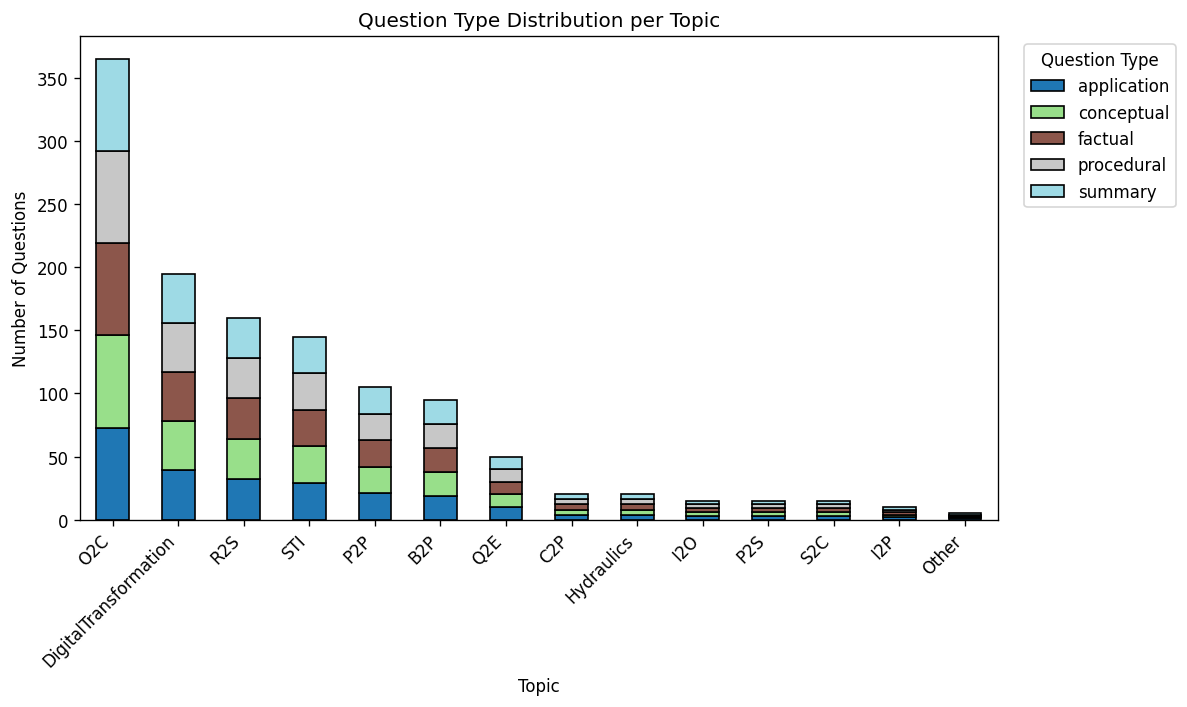

question_type          application  conceptual  factual  procedural  summary
topic                                                                       
O2C                             73          73       73          73       73
DigitalTransformation           39          39       39          39       39
R2S                             32          32       32          32       32
STI                             29          29       29          29       29
P2P                             21          21       21          21       21
B2P                             19          19       19          19       19
Q2E                             10          10       10          10       10
C2P                              4           4        4           4        4
Hydraulics                       4           4        4           4        4
I2O                              3           3        3           3        3
P2S                              3           3        3           3        3

In [5]:
# Cross-tabulation: rows = topic, columns = question_type
ct = pd.crosstab(df["topic"], df["question_type"])

# Order topics by total count (largest first) for readability
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 6))
ct.plot(kind="bar", stacked=True, colormap="tab20", edgecolor="black", ax=ax)

ax.set_title("Question Type Distribution per Topic")
ax.set_xlabel("Topic")
ax.set_ylabel("Number of Questions")
plt.xticks(rotation=45, ha="right")
ax.legend(title="Question Type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

print(ct)   # the full counts table


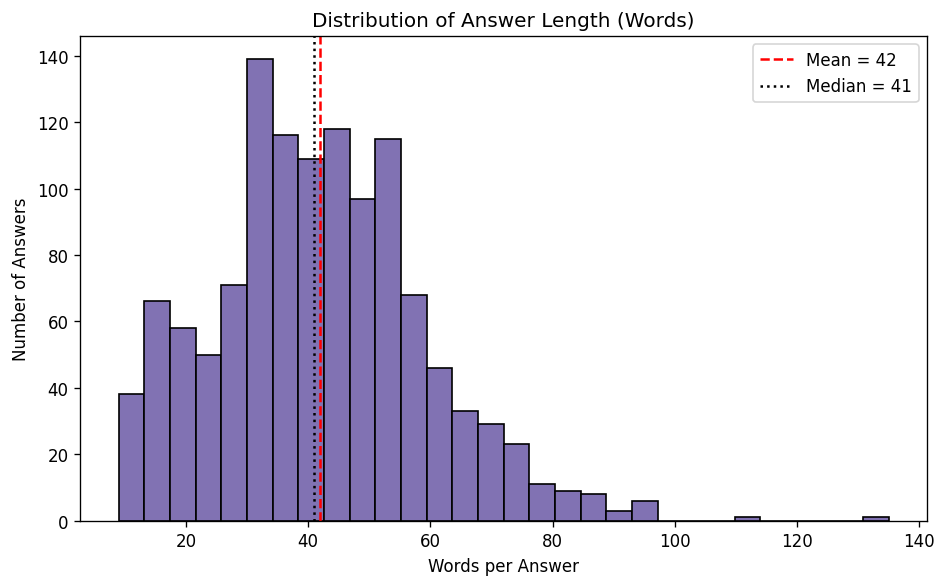

count    1215.0
mean       41.9
std        17.2
min         9.0
25%        30.0
50%        41.0
75%        52.5
max       135.0
Name: answer_words, dtype: float64


In [6]:
# Word count per answer (handles missing values safely)
df["answer_words"] = df["answer"].fillna("").astype(str).str.split().str.len()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["answer_words"], bins=30, color="#8172B3", edgecolor="black")

ax.set_title("Distribution of Answer Length (Words)")
ax.set_xlabel("Words per Answer")
ax.set_ylabel("Number of Answers")

# reference lines for mean & median
mean_v = df["answer_words"].mean()
median_v = df["answer_words"].median()
ax.axvline(mean_v, color="red", linestyle="--", linewidth=1.5, label=f"Mean = {mean_v:.0f}")
ax.axvline(median_v, color="black", linestyle=":", linewidth=1.5, label=f"Median = {median_v:.0f}")
ax.legend()

plt.tight_layout()
plt.show()

# summary stats for your thesis text
print(df["answer_words"].describe().round(1))


C:\Users\VAS1UL\AppData\Local\Temp\ipykernel_37432\2974680349.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_lvl, labels=level_order, showmeans=True)
C:\Users\VAS1UL\AppData\Local\Temp\ipykernel_37432\2974680349.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_qt, labels=qt_order, showmeans=True)


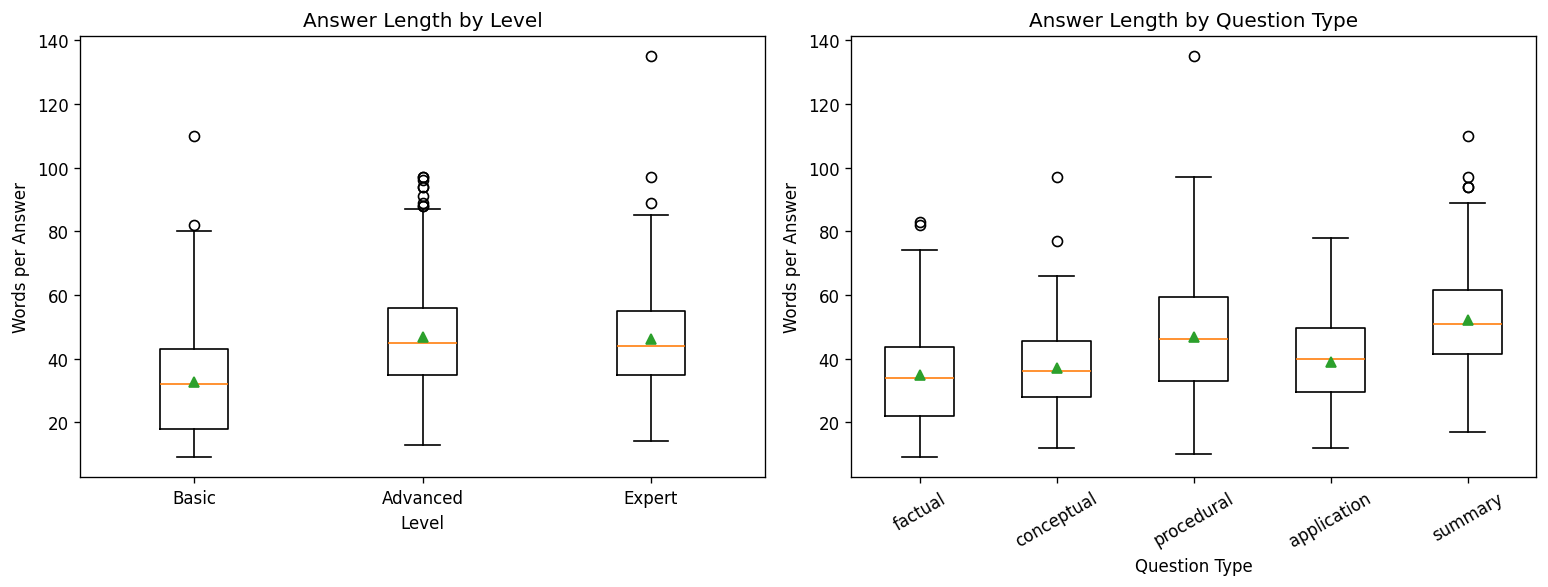

By level:
 level
Advanced    45.0
Basic       32.0
Expert      44.0
Name: answer_words, dtype: float64

By question type:
 question_type
application    40.0
conceptual     36.0
factual        34.0
procedural     46.0
summary        51.0
Name: answer_words, dtype: float64


In [11]:
# ensure the word-count column exists
if "answer_words" not in df.columns:
    df["answer_words"] = df["answer"].fillna("").astype(str).str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: grouped by difficulty level (ordered) ---
# Actual levels: Basic, Advanced, Expert (no "Intermediate")
preferred = ["Basic", "Advanced", "Expert"]
level_order = [l for l in preferred if l in df["level"].unique()]
level_order += [l for l in df["level"].dropna().unique() if l not in level_order]  # safety net
data_lvl = [df.loc[df["level"] == l, "answer_words"] for l in level_order]

axes[0].boxplot(data_lvl, labels=level_order, showmeans=True)
axes[0].set_title("Answer Length by Level")
axes[0].set_xlabel("Level")
axes[0].set_ylabel("Words per Answer")

# --- Right: grouped by question type ---
qt_order = df["question_type"].value_counts().index.tolist()
data_qt = [df.loc[df["question_type"] == q, "answer_words"] for q in qt_order]

axes[1].boxplot(data_qt, labels=qt_order, showmeans=True)
axes[1].set_title("Answer Length by Question Type")
axes[1].set_xlabel("Question Type")
axes[1].set_ylabel("Words per Answer")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# median answer length per group
print("By level:\n", df.groupby("level")["answer_words"].median())
print("\nBy question type:\n", df.groupby("question_type")["answer_words"].median())


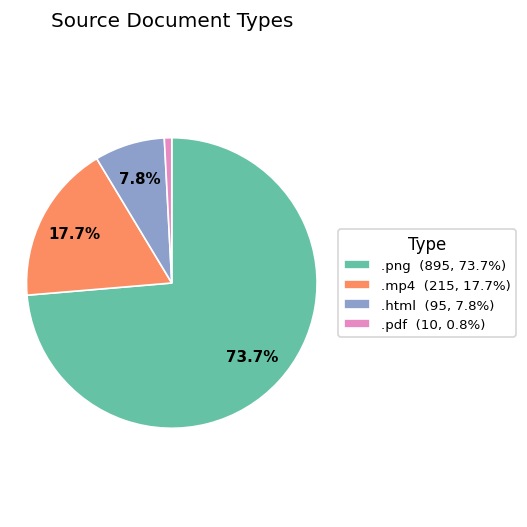

In [9]:
counts = df["type"].value_counts()
total = counts.sum()

fig, ax = plt.subplots(figsize=(4.5, 4.5))     # smaller
colors = plt.cm.Set2.colors

wedges, _, autotexts = ax.pie(
    counts,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",   # hide % on tiny slices
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)
plt.setp(autotexts, size=9, weight="bold")

ax.set_title("Source Document Types", pad=15)
ax.axis("equal")

# legend with counts, outside the pie -> no overlap with title
labels = [f"{t}  ({c}, {c/total*100:.1f}%)" for t, c in counts.items()]
ax.legend(wedges, labels, title="Type",
          loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)

plt.tight_layout()
plt.show()
